In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import umap
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sns.set_theme(style="darkgrid")

df = pd.read_csv("data/kr_pl_worldcover_2023.csv")

In [3]:
df_clean = df.dropna(subset=['label'])
print(f"Points after dropping nulls: {len(df_clean)}")
print(df_clean['label_name'].value_counts())

Points after dropping nulls: 92589
label_name
Tree cover                37233
Cropland                  30542
Grassland                 17690
Permanent water bodies     4109
Built-up                   2591
Herbaceous wetland          323
Bare/sparse vegetation       94
Moss and lichen               5
Shrubland                     2
Name: count, dtype: int64


In [4]:
min_count = df_clean['label'].value_counts().min()
df_balanced = df_clean.groupby('label').sample(n=min_count, random_state=42)

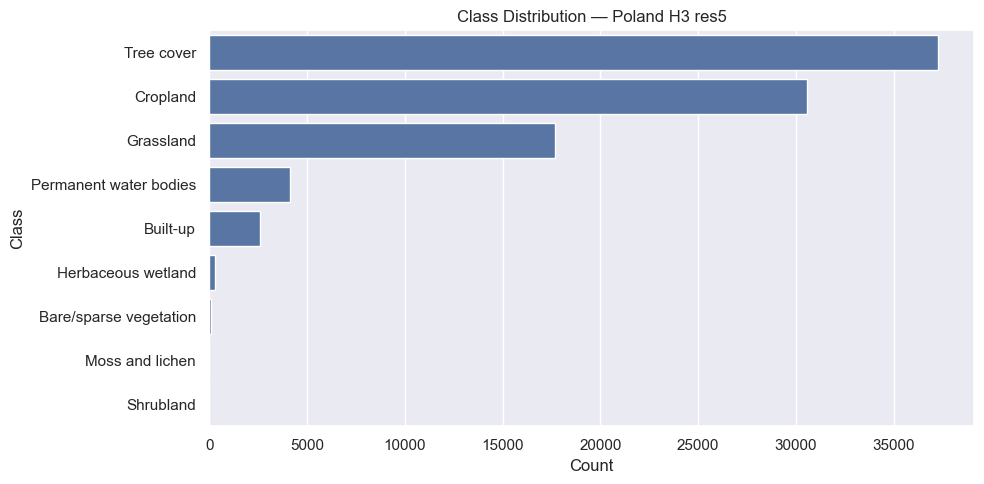

In [5]:
plt.figure(figsize=(10, 5))
order = df['label_name'].value_counts().index
sns.countplot(data=df, y='label_name', order=order)
plt.xlabel('Count')
plt.ylabel('Class')
plt.title('Class Distribution — Poland H3 res5')
plt.tight_layout()
plt.show()

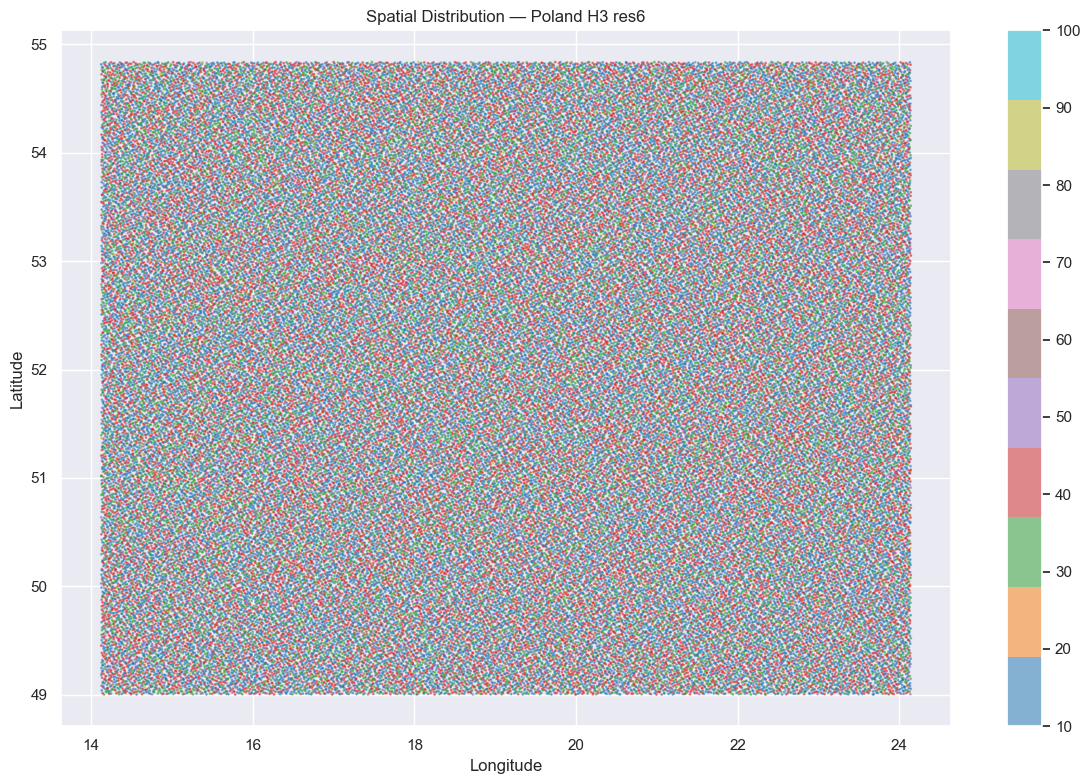

In [6]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    df_clean['lon'], 
    df_clean['lat'],
    c=df_clean['label'],
    cmap='tab10',
    s=1,
    alpha=0.5
)
plt.colorbar(scatter)
plt.title('Spatial Distribution — Poland H3 res6')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()

/Users/pstano/Documents/applications/lucera/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


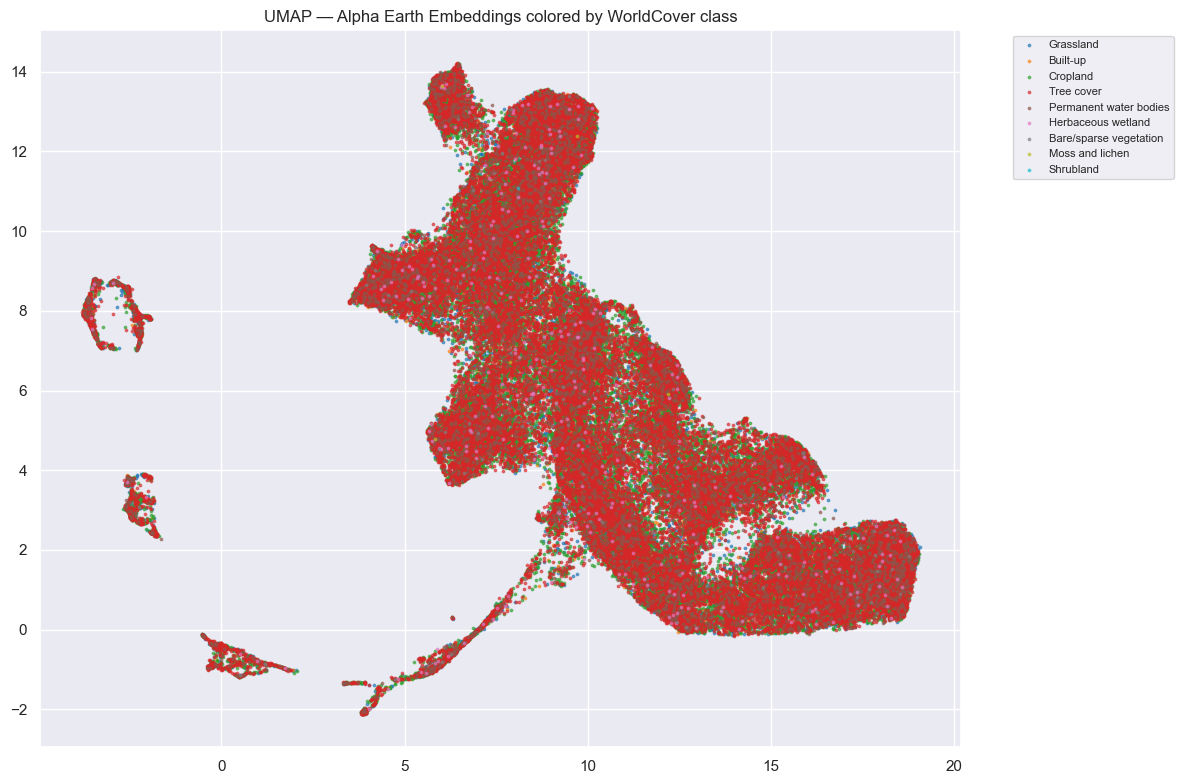

In [7]:
embedding_cols = [c for c in df_clean.columns if c.startswith('A')]
X = df_clean[embedding_cols].values
y = df_clean['label_name'].values

reducer = umap.UMAP(random_state=42, n_neighbors=15, min_dist=0.1)
embedding_2d = reducer.fit_transform(X)

plt.figure(figsize=(12, 8))
classes = df_clean['label_name'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    mask = y == cls
    plt.scatter(
        embedding_2d[mask, 0],
        embedding_2d[mask, 1],
        c=[color],
        label=cls,
        s=3,
        alpha=0.6
    )

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.title('UMAP — Alpha Earth Embeddings colored by WorldCover class')
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'PCA — how many dimensions matter?')

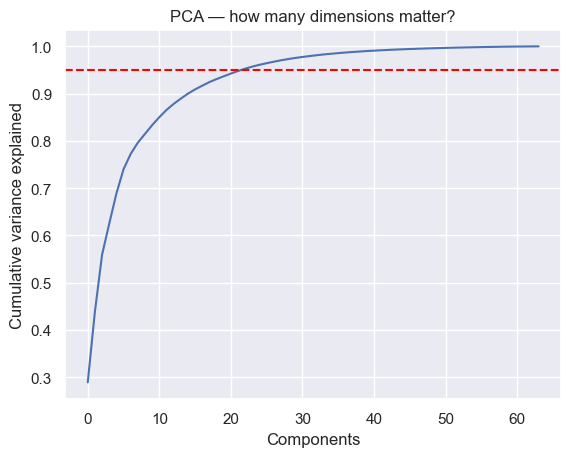

In [8]:
pca = PCA()
pca.fit(X)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Components')
plt.ylabel('Cumulative variance explained')
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.title('PCA — how many dimensions matter?')

In [9]:
iso = IsolationForest(contamination=0.02, random_state=42)
outliers = iso.fit_predict(X)
print(f"Outliers detected: {(outliers == -1).sum()}")
df_clean = df_clean[outliers == 1]

Outliers detected: 1852


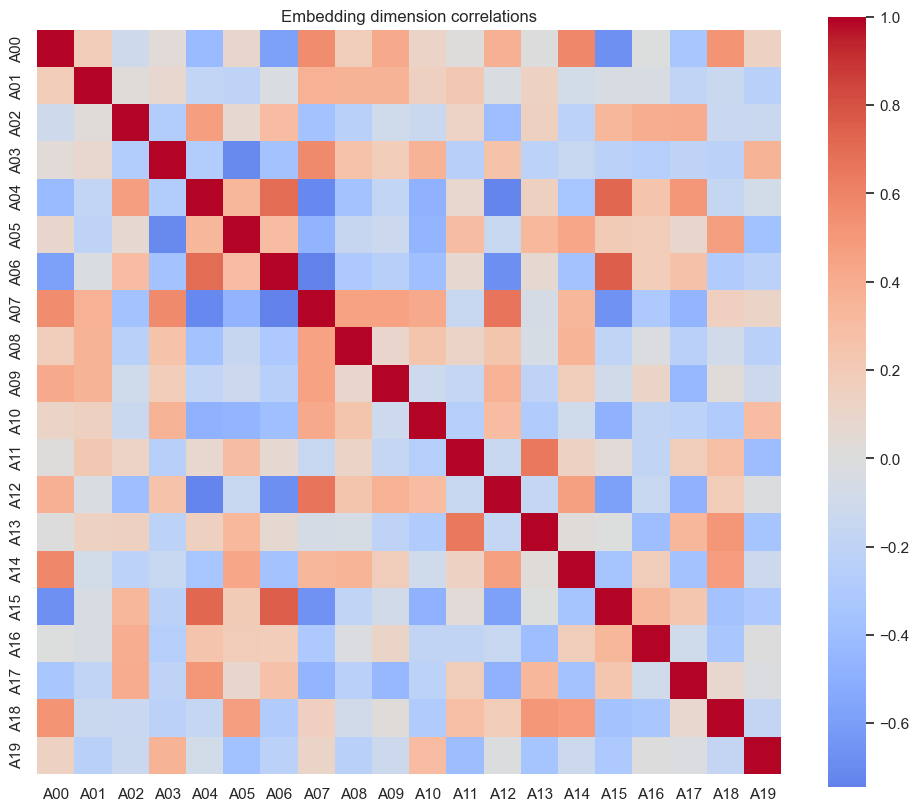

In [10]:
embed_cols = [c for c in df_clean.columns if c.startswith('A')][:20]
X_df = df_clean[embed_cols]
plt.figure(figsize=(12, 10))
sns.heatmap(X_df.corr(), cmap='coolwarm', center=0, square=True)
plt.title('Embedding dimension correlations')
plt.show()

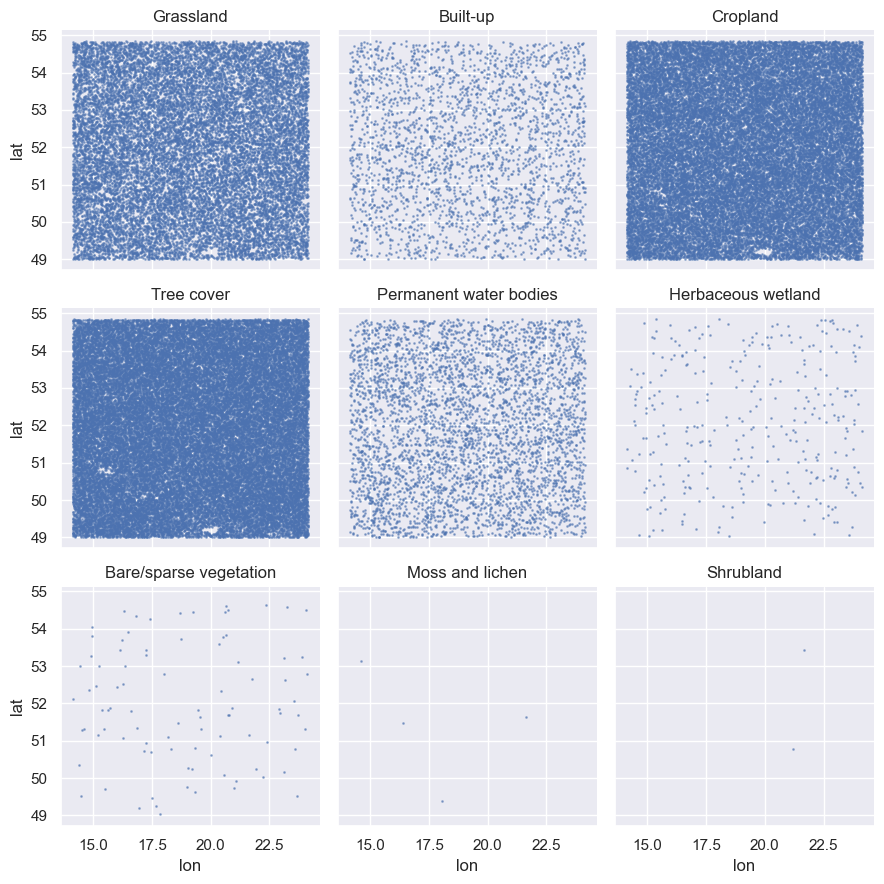

In [11]:
g = sns.FacetGrid(df_clean, col='label_name', col_wrap=3, height=3)
g.map(plt.scatter, 'lon', 'lat', s=1, alpha=0.5)
g.set_titles('{col_name}')
plt.show()